# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.

Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial. 
But are they?

4. Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Micaiah Lee, Fal Elgizouli, Payton Gergen

**Date:** 2026-11-16

1. Check out the data set `heart_failure` and appropriately clean it.


In [1]:
# Your Phase 1 solution to the problem goes here.
# Micaiah
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path("data/heart_failure")
df_dirty = pd.read_csv(DATA_DIR / "heart_failure_clinical_records_dataset.csv")
df_dirty.head()

# Dataset looks clean and all columns look relevant.
# Clean df will be df
df = df_dirty
df.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.


In [2]:
# Micaiah
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
from sklearn import metrics
seed = 0

# Define a function to train-test split
def traintest(input_df, seed):
    df_train, df_test = train_test_split(df, test_size=0.2, random_state=seed)
    print(df_train.shape, df_test.shape)
    return(df_train, df_test)


def modeling(df, seed):
    print("seed: ", seed)

    # Implement split
    [df_train, df_test] = traintest(df, seed=seed)


    # Defining what features we're interested in
    features = ['age',	'anaemia',	'creatinine_phosphokinase',	'diabetes',	'ejection_fraction',	'high_blood_pressure',	'platelets',	'serum_creatinine',	'serum_sodium',	'sex',	'smoking',	'time']
    classes = ['Alive', 'Dead']

    df_train.head()

    # Defining the x and y values for training and testing
    y_train = df_train["DEATH_EVENT"]
    x_train = df_train[features]

    y_test = df_test["DEATH_EVENT"]
    x_test = df_test[features]

    y_ = df["DEATH_EVENT"]
    x_ = df[features]


    # Implement a decision tree classifier
    tree = DecisionTreeClassifier(random_state = seed).fit(x_train, y_train)
    y_hat_tree = tree.predict(x_test)

    pd.crosstab(y_test, y_hat_tree,
                rownames=["Actual"], colnames=["Predicted"])

    # plt.figure(figsize = (20, 20), dpi =300)
    # plot_tree(tree, feature_names = features, class_names = classes)
    tree_accuracy = metrics.accuracy_score(y_test, y_hat_tree)
    print("Decision Tree Accuracy:",metrics.accuracy_score(y_test, y_hat_tree))


    # Implement a Linear Regression
    linear = LogisticRegression(random_state=seed, max_iter=10000).fit(x_train, y_train)
    y_hat_linear = linear.predict(x_test)

    pd.crosstab(y_test, y_hat_linear,
                rownames=["Actual"], colnames=["Predicted"])

    linear_accuracy = metrics.accuracy_score(y_test, y_hat_linear)
    print("Logistic Regression Accuracy:",metrics.accuracy_score(y_test, y_hat_linear))

    # Return
    return(tree, linear, tree_accuracy, linear_accuracy)

# Create the model with the seed 0
[tree0, linear0, tree0_accuracy, linear0_accuracy] = modeling(df, seed=0)

seed:  0
(239, 13) (60, 13)
Decision Tree Accuracy: 0.75
Logistic Regression Accuracy: 0.7833333333333333


3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.

In [3]:
# Micaiah

# Initialize empty lists
tree_list = []
linear_list = []
tree_accuracy_list = []
linear_accuracy_list = []

# Iterate and append (not super efficient but whatever)
for i in range(1, 6):
    [tree_placeholder, linear_placeholder, tree_accuracy_placeholder, linear_accuracy_placeholder] = modeling(df, seed=i)
    tree_list.append(tree_placeholder)
    linear_list.append(linear_placeholder)
    tree_accuracy_list.append(tree_accuracy_placeholder)
    linear_accuracy_list.append(linear_accuracy_placeholder)

seed:  1
(239, 13) (60, 13)
Decision Tree Accuracy: 0.8
Logistic Regression Accuracy: 0.8833333333333333
seed:  2
(239, 13) (60, 13)
Decision Tree Accuracy: 0.8666666666666667
Logistic Regression Accuracy: 0.8666666666666667
seed:  3
(239, 13) (60, 13)
Decision Tree Accuracy: 0.75
Logistic Regression Accuracy: 0.8333333333333334
seed:  4
(239, 13) (60, 13)
Decision Tree Accuracy: 0.7666666666666667
Logistic Regression Accuracy: 0.8333333333333334
seed:  5
(239, 13) (60, 13)
Decision Tree Accuracy: 0.7666666666666667
Logistic Regression Accuracy: 0.85


4. Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?



(239, 13) (60, 13)


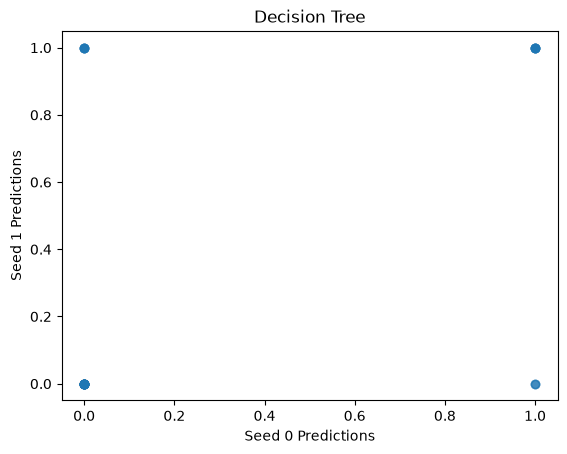

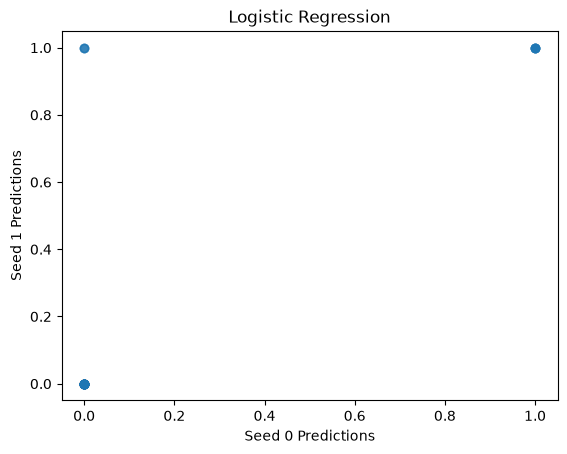

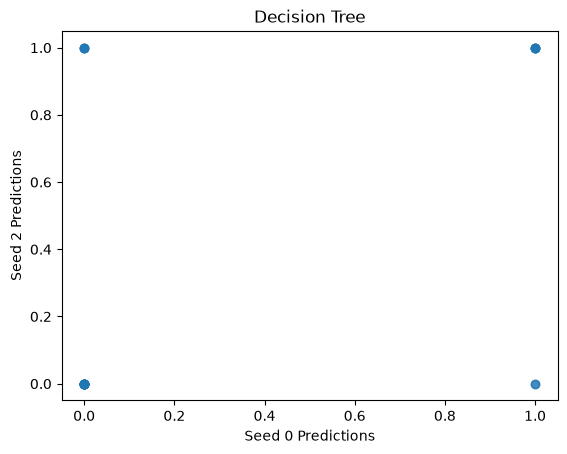

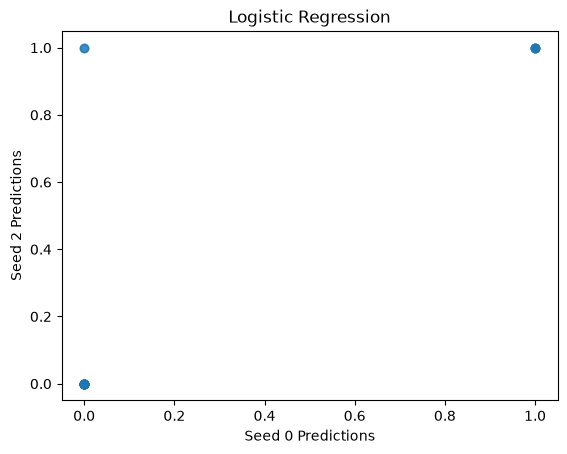

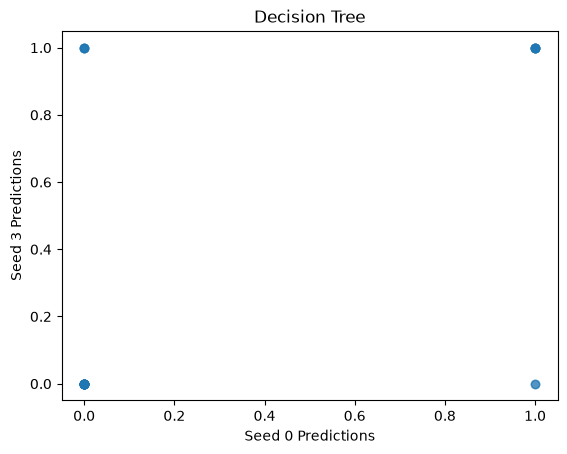

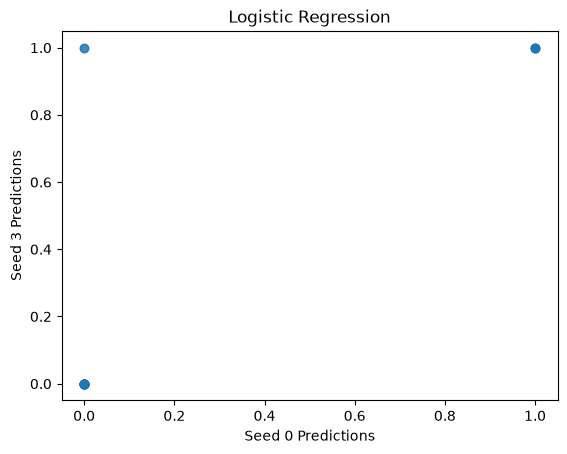

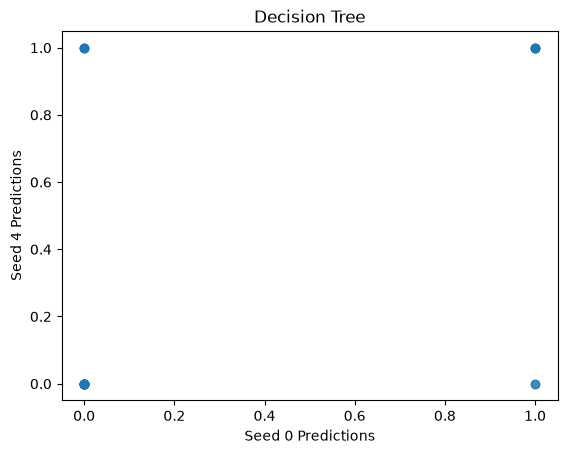

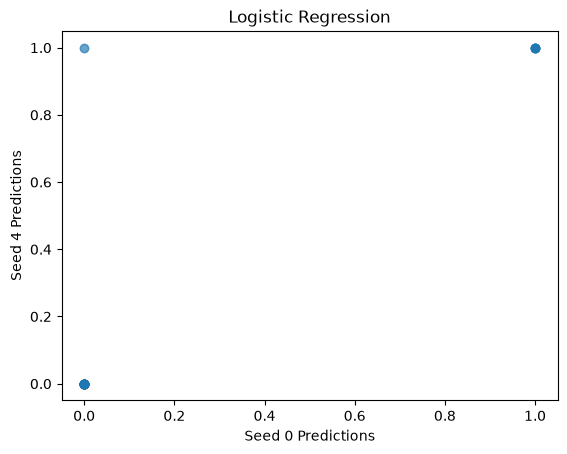

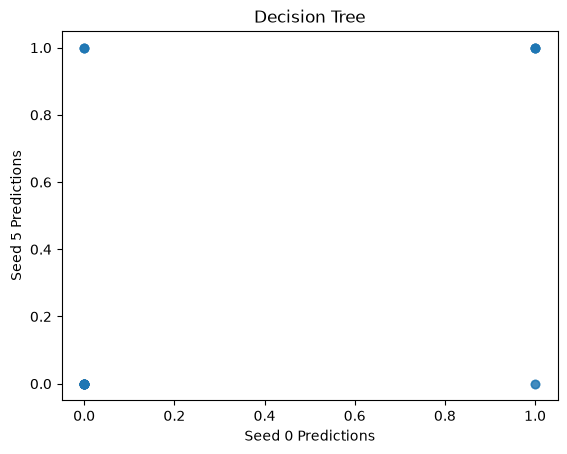

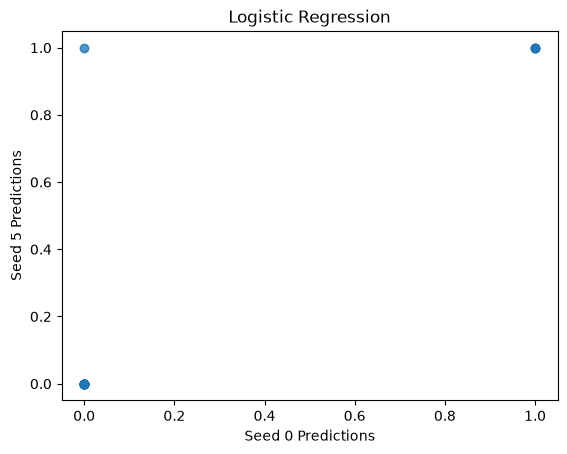

Seed: 1
decision Tree correlation: 0.4305875564144615
logistic regression correlation: 0.7637626158259734
Seed: 2
decision Tree correlation: 0.45630518910673146
logistic regression correlation: 0.7952062255644575
Seed: 3
decision Tree correlation: 0.5311093184684906
logistic regression correlation: 0.7952062255644573
Seed: 4
decision Tree correlation: 0.4563051891067315
logistic regression correlation: 0.8660254037844389
Seed: 5
decision Tree correlation: 0.45630518910673146
logistic regression correlation: 0.8291561975888498
Seed: 1
decision tree intercept: 0.261904761904762
decision tree slope: 0.46031746031746007
decision tree r2: 0.18540564373897706
logistic regression intercept: 0.12500000000000017
logistic regression slope: 0.8749999999999991
logistic regression r2: 0.5833333333333335
Seed: 2
decision tree intercept: 0.23809523809523817
decision tree slope: 0.48412698412698396
decision tree r2: 0.20821442560573022
logistic regression intercept: 0.10416666666666663
logistic regres

In [4]:
#  fal

#4a
df_train, df_test = traintest(df, seed=0)

for i in range(5):

    plt.scatter(tree0.predict(df_test[tree0.feature_names_in_]), tree_list[i].predict(df_test[tree0.feature_names_in_]), alpha=0.3)
    plt.xlabel("Seed 0 Predictions")
    plt.ylabel("Seed " + str(i+1) + " Predictions")
    plt.title("Decision Tree")
    plt.show()

    plt.scatter(linear0.predict(df_test[linear0.feature_names_in_]), linear_list[i].predict(df_test[linear0.feature_names_in_]), alpha=0.3)
    plt.xlabel("Seed 0 Predictions")
    plt.ylabel("Seed " + str(i+1) + " Predictions")
    plt.title("Logistic Regression")
    plt.show()

# predictions appear reasonably similar but there is a lot of overlap so visually clear similarity cannot be determined.

#4b
for i in range(5):

    print("Seed:", i+1)
    tree_corr = np.corrcoef(tree0.predict(df_test[tree0.feature_names_in_]), tree_list[i].predict(df_test[tree0.feature_names_in_]))[0, 1]
    print("decision Tree correlation:", tree_corr)

    linear_corr = np.corrcoef(
        linear0.predict(df_test[linear0.feature_names_in_]),
        linear_list[i].predict(df_test[linear0.feature_names_in_]))[0, 1]

    print("logistic regression correlation:", linear_corr)

# the decision trees are correalated but not highly with vallues around 0.4 and 0.5. the logistic trees are more correalated with values 
# around .7 and .8.


#4c
from sklearn.linear_model import LinearRegression

for i in range(5):

    print("Seed:", i+1)

    # decision tree

    tree_reg = LinearRegression().fit(tree0.predict(df_test[tree0.feature_names_in_]).reshape(-1, 1),tree_list[i].predict(df_test[tree0.feature_names_in_]))

    print("decision tree intercept:", tree_reg.intercept_)
    print("decision tree slope:", tree_reg.coef_[0])
    print("decision tree r2:", tree_reg.score(

    tree0.predict(df_test[tree0.feature_names_in_]).reshape(-1, 1), tree_list[i].predict(df_test[tree0.feature_names_in_])))

    # logistic regression

    linear_reg = LinearRegression().fit(linear0.predict(df_test[linear0.feature_names_in_]).reshape(-1, 1), linear_list[i].predict(df_test[linear0.feature_names_in_]))

    print("logistic regression intercept:", linear_reg.intercept_)
    print("logistic regression slope:", linear_reg.coef_[0])
    print("logistic regression r2:", linear_reg.score(

    linear0.predict(df_test[linear0.feature_names_in_]).reshape(-1, 1), linear_list[i].predict(df_test[linear0.feature_names_in_])))

# the decision trees have intercepts farther from 0 and slopes farther from 1 with 
# low r2 values around .1 and .2. logistic regression has intercepts
# closer to 0 and slopes closer to 1 with higher r2 values around .5 and .6.
# neither is perfectly stable, but logistic regression is more consistent
# across the different seeds

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?


6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [5]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]